## ARIA-PROMOTE - WP7 Sea Surface Validation


### Description:

Notebook developing evaluation and validation diagnostics for WP7 eORCA025_SPNA20 simulation.

### Contact:

Ollie Tooth (oliver.tooth@noc.ac.uk)

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import icechunk
import matplotlib.pyplot as plt
import xarray as xr
import xesmf as xe
from nemo_cookbook import NEMODataTree

### Access Ocean Observations via OceanDataStore - latest STAC:

In [2]:
from OceanDataStore import OceanDataCatalog

catalog = OceanDataCatalog(catalog_name="ods-stac")
catalog

Collection ID,Title,Description,From,To
noc-rapid-evolution,NOC RAPID-Evolution Collection,"SummaryAbout: Collection of nested ocean model simulations produced by the National Oceanography Centre (NOC) as part of the CCROC RAPID-Evolution project delivered through a partnership between UK (National Oceanography Centre, Met Office) and US (University of Miami and NOAA's AOML). More Information: - [RAPID-Evolution](https://rapid.ac.uk/rapid-evolution)",1976-01-01,2023-12-31
noc-npd-jra55,NOC Near-Present Day JRA55-do Collection,SummaryAbout: Collection of multi-decadal Near-Present Day ocean model hindcast simulations produced by the National Oceanography Centre (NOC) using JRA55-do atmospheric forcing as part of the Atlantic Climate and Environment Strategic Science (AtlantiS) programme. More Information: - [AtlantiS](https://atlantis.ac.uk) - [NOC Near-Present Day](https://noc-msm.github.io/NOC_Near_Present_Day/),1976-01-01,2024-02-01
noc-npd-era5,NOC Near-Present Day ERA-5 Collection,SummaryAbout: Collection of multi-decadal Near-Present Day ocean model hindcast simulations produced by the National Oceanography Centre (NOC) using bias-corrected ERA-5 atmospheric forcing as part of the Atlantic Climate and Environment Strategic Science (AtlantiS) programme. More Information: - [AtlantiS](https://atlantis.ac.uk) - [NOC Near-Present Day](https://noc-msm.github.io/NOC_Near_Present_Day/),1976-01-01,2026-05-15
nsidc,"NSIDC Sea Ice Index, Version 4 Collection","SummaryAbout: Collection of National Snow and Ice Data Center (NSIDC) Sea Ice Index, Version 4 datasets. More Information: - [NSIDC](https://nsidc.org/home)",1978-11-15,2025-12-15
woa23,World Ocean Atlas 2023 Collection,SummaryAbout: Collection of World Ocean Atlas 2023 climatology datasets. More Information: - [World Ocean Atlas](https://www.ncei.noaa.gov/access/world-ocean-atlas-2023/),1971-01-01,2020-12-31
oisst,OISST Version 2.1 Collection,SummaryAbout: Collection of OISST Version 2.1 datasets. More Information: - [OISST Version 2.1](https://psl.noaa.gov/data/gridded/data.noaa.oisst.v2.highres.html),1981-09-01,2026-09-01
en4.2.2,EN4.2.2 Collection,SummaryAbout: Collection of EN4.2.2 quality Controlled Ocean datasets. More Information: - [EN4.2.2](https://www.metoffice.gov.uk/hadobs/en4/),1950-01-01,2026-08-15
armor3d,ARMOR3D Collection,SummaryAbout: Collection of Multi Observation Global Ocean ARMOR3D Temperature Salinity Height Geostrophic Current and MLD. More Information: - [ARMOR3D](https://data.marine.copernicus.eu/product/MULTIOBS_GLO_PHY_TSUV_3D_MYNRT_015_012/description),1993-01-01,2024-12-31
hadisst,HadISST Version 1.1 Collection,SummaryAbout: Collection of HadISST Version 1.1 datasets. More Information: - [HadISST Version 1.1](https://www.metoffice.gov.uk/hadobs/hadisst/),1870-01-16,2026-04-16
era5,ERA5 Collection,SummaryAbout: Collection of ERA5 datasets. More Information: - [ERA5](https://www.ecmwf.int/en/forecasts/datasets/reanalysis-datasets/era5),1980-01-01,2026-06-20


### 1.1 Utility Function

* Define helper function to open Virtual NEMODataTrees from local Icechunk repositories.

* **To do:** Add notes on tips & tricks for virtualizing (dropping variables and loadable variables).

* **To do:** Add notes on creating combined domain_cfg + mesh_masks for virtualizing nested NEMODataTrees.

In [3]:
def open_virtual_NEMODataTree(
        repo_path: str,
        name: str,
        branch: str = "main",
        iperio: bool = True,
        nftype: str = "T",
    ) -> NEMODataTree:
    # Open Icechunk repository to identify virtual chunk container prefix path:
    repo_ini = icechunk.Repository.open(storage=icechunk.local_filesystem_storage(repo_path))
    store_path = next(iter(repo_ini.config.virtual_chunk_containers.keys()))

    # Authorise Icechunk to fetch virtual chunks from the original NetCDF files on our local filesystem:
    credentials = icechunk.credentials.containers_credentials({store_path: icechunk.credentials.LocalFileSystemAccess})

    # Open Icechunk repository stored & authorise virtual chunk access:
    repo = icechunk.Repository.open(storage=icechunk.local_filesystem_storage(repo_path),
                                                authorize_virtual_chunk_access=credentials
                                                )

    # Create virtual NEMODataTree from Icechunk repository:
    nemo = NEMODataTree.from_icechunk(repo=repo,
                                      branch=branch,
                                      iperio=iperio,
                                      nftype=nftype,
                                      name=name,
                                      )

    return nemo

### Open PROMOTE eORCA025 SPNA20 nested NEMODataTree:

In [5]:
nemo = open_virtual_NEMODataTree(
    repo_path="/dssgfs01/working/otooth/PROMOTE/repos/eORCA025_SPNA20_1m",
    name="eORCA025 SPNA20 JRA55-do",
    iperio=True,
    nftype="T",
)

# nemo["gridT"].dataset = nemo["gridT"].dataset.rename({"thkcello": "e3t"})
# nemo["gridT/1_gridT"].dataset = nemo["gridT/1_gridT"].dataset.rename({"thkcello": "e3t"})

nemo

  2026-11-25T09:29:46.029499Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:343

  2026-11-25T09:29:46.042591Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:343



<xarray.DataTree 'eORCA025 SPNA20 JRA55-do'>
Group: /
│   Attributes:
│       nftype:   T
│       iperio:   True
├── Group: /gridT
│   │   Dimensions:               (time_counter: 792, j: 1206, i: 1440, k: 75,
│   │                              axis_nbounds: 2)
│   │   Coordinates:
│   │     * time_counter          (time_counter) datetime64[ns] 6kB 1958-01-16T12:00:...
│   │       time_centered         (time_counter) datetime64[ns] 6kB dask.array<chunksize=(1,), meta=np.ndarray>
│   │     * j                     (j) int64 10kB 1 2 3 4 5 ... 1202 1203 1204 1205 1206
│   │     * i                     (i) int64 12kB 1 2 3 4 5 ... 1436 1437 1438 1439 1440
│   │       gphit                 (j, i) float64 14MB dask.array<chunksize=(1206, 1440), meta=np.ndarray>
│   │       glamt                 (j, i) float64 14MB dask.array<chunksize=(1206, 1440), meta=np.ndarray>
│   │     * k                     (k) int64 600B 1 2 3 4 5 6 7 ... 69 70 71 72 73 74 75
│   │       deptht                (k) float32 300B dask.array<chunksize=(75,), meta=np.ndarray>
│   │   Dimensions without coordinates: axis_nbounds
│   │   Data variables: (12/23)
│   │       hfds                  (time_counter, j, i) float32 6GB dask.array<chunksize=(1, 1206, 1440), meta=np.ndarray>
│   │       e1t                   (j, i) float64 14MB dask.array<chunksize=(1206, 1440), meta=np.ndarray>
│   │       hfto                  (time_counter, j, i) float32 6GB dask.array<chunksize=(1, 1206, 1440), meta=np.ndarray>
│   │       e2t                   (j, i) float64 14MB dask.array<chunksize=(1206, 1440), meta=np.ndarray>
│   │       e3t                   (time_counter, k, j, i) float32 413GB dask.array<chunksize=(1, 3, 1206, 1440), meta=np.ndarray>
│   │       friver                (time_counter, j, i) float32 6GB dask.array<chunksize=(1, 1206, 1440), meta=np.ndarray>
│   │       ...                    ...
│   │       sowaflup              (time_counter, j, i) float32 6GB dask.array<chunksize=(1, 1206, 1440), meta=np.ndarray>
│   │       thetao_con            (time_counter, k, j, i) float32 413GB dask.array<chunksize=(1, 3, 1206, 1440), meta=np.ndarray>
│   │       tos_con               (time_counter, j, i) float32 6GB dask.array<chunksize=(1, 1206, 1440), meta=np.ndarray>
│   │       tmask                 (k, j, i) int8 130MB dask.array<chunksize=(75, 1206, 1440), meta=np.ndarray>
│   │       time_centered_bounds  (time_counter, axis_nbounds) datetime64[ns] 13kB dask.array<chunksize=(1, 2), meta=np.ndarray>
│   │       zos                   (time_counter, j, i) float32 6GB dask.array<chunksize=(1, 1206, 1440), meta=np.ndarray>
│   │   Attributes:
│   │       name:         OUTPUT/eORCA025_SPNA20_1m_grid_T
│   │       description:  monthly scalar ocean variables defined on NEMO curvilinear ...
│   │       title:        monthly scalar ocean variables defined on NEMO curvilinear ...
│   │       Conventions:  CF-1.6
│   └── Group: /gridT/1_gridT
│           Dimensions:               (time_counter: 792, k1: 75, axis_nbounds: 2,
│                                      j1: 1243, i1: 1308, k: 75)
│           Coordinates:
│               time_centered         (time_counter) datetime64[ns] 6kB dask.array<chunksize=(1,), meta=np.ndarray>
│             * k1                    (k1) int64 600B 1 2 3 4 5 6 7 ... 69 70 71 72 73 74 75
│               1_deptht              (k1) float32 300B dask.array<chunksize=(75,), meta=np.ndarray>
│             * j1                    (j1) int64 10kB 1 2 3 4 5 ... 1239 1240 1241 1242 1243
│               j_j1                  (j1) float64 10kB dask.array<chunksize=(1243,), meta=np.ndarray>
│             * i1                    (i1) int64 10kB 1 2 3 4 5 ... 1304 1305 1306 1307 1308
│               1_glamt               (j1, i1) float64 13MB dask.array<chunksize=(1243, 1308), meta=np.ndarray>
│               1_gphit               (j1, i1) float64 13MB dask.array<chunksize=(1243, 1308), meta=np.ndarray>
│               i_i1                  (i1) float64 10kB das

Text(0.5, 1.0, 'Sea Surface Temperature\nTime-Mean [eORCA025 + SPNA20]')

<Figure size 640x480 with 0 Axes>

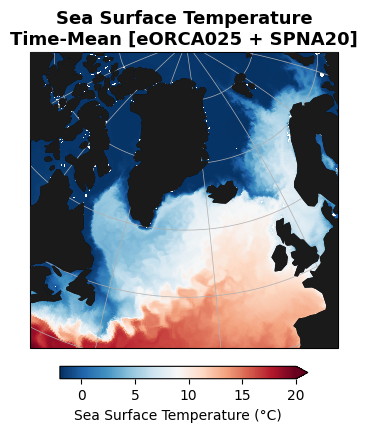

In [6]:
# Define subpolar North Atlantic boundary box for analysis:
bbox_spna = (-65, 0, 42, 88)  # (-65°E, -0°E, 42°N, 88°N)

plt.figure()
# Plot the sea surface temperature (°C) in the subpolar North Atlantic region:
(nemo["gridT/tos_con"]
 .isel(time_counter=120)
 .geoplot(projection=ccrs.Orthographic(central_longitude=-32, central_latitude=55),
          extent=bbox_spna,
          cmap='RdBu_r',
          clabel_kwargs={'label': 'Sea Surface Temperature (°C)'},
          vmin=-2,
          vmax=20,
          cbar_kwargs={'extend': "max"}
          )
 )
plt.title('Sea Surface Temperature\nTime-Mean [eORCA025 + SPNA20]', fontsize=13, fontweight='bold')

### Comparing eORCA025 SPNA20 MLDs to Observations

* Options are: LOPS (de Boyer Montégut et al., 2023) or ARMOR-3D via ODS.

In [7]:
ds_obs = catalog.open_dataset(id="lops/lops_mld_1970_2021_monthly_climatology")
ds_obs

<xarray.Dataset> Size: 7MB
Dimensions:    (latitude: 180, longitude: 360, month: 12, bnds: 2)
Coordinates:
  * latitude   (latitude) float32 720B -89.5 -88.5 -87.5 ... 87.5 88.5 89.5
  * longitude  (longitude) float32 1kB -179.5 -178.5 -177.5 ... 178.5 179.5
  * month      (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
Dimensions without coordinates: bnds
Data variables:
    dx         (latitude, longitude) float32 259kB dask.array<chunksize=(180, 360), meta=np.ndarray>
    cell_area  (latitude, longitude) float32 259kB dask.array<chunksize=(180, 360), meta=np.ndarray>
    mask       (latitude, longitude) int16 130kB dask.array<chunksize=(180, 360), meta=np.ndarray>
    time_bnds  (month, bnds) datetime64[ns] 192B dask.array<chunksize=(12, 2), meta=np.ndarray>
    n_obs      (month, latitude, longitude) int32 3MB dask.array<chunksize=(12, 180, 360), meta=np.ndarray>
    mld_dr003  (month, latitude, longitude) float32 3MB dask.array<chunksize=(12, 180, 360), meta=np.ndarray>
    dy         (latitude, longitude) float32 259kB dask.array<chunksize=(180, 360), meta=np.ndarray>
Attributes: (12/21)
    Conventions:                 CF-1.6
    title:                       Monthly climatology of the oceanic mixed lay...
    description:                 Mixed layer depth climatology computed with ...
    source:                      This MLD climatology is generated by monthly...
    dataset_type:                observation
    product_type:                climatology
    ...                          ...
    horizontal_grid_resolution:  1 degree
    aggregation:                 mean
    aggregation_frequency:       monthly
    status:                      completed
    update_frequency:            None
    bbox:                        [-180.0, 180.0, -90.0, 90.0]

Text(0.5, 1.0, 'March Mixed Layer Depth\n(1980-2021) [eORCA025 + SPNA20]')

<Figure size 640x480 with 0 Axes>

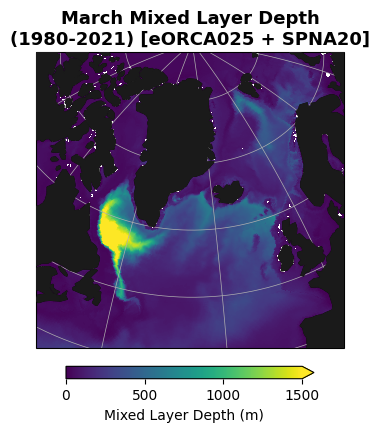

In [19]:
# Define subpolar North Atlantic boundary box for analysis:
bbox_spna = (-65, 0, 42, 88)  # (-65°E, -0°E, 42°N, 88°N)

plt.figure()
# Plot March Mixed Layer Depth (m) in the subpolar North Atlantic region:
(nemo["gridT/mlotst"]
 .isel(time_counter=nemo["gridT/time_counter"].dt.month==3)
 .sel(time_counter=slice("1980-01", "2021-12"))
 .mean(dim="time_counter")
 .geoplot(projection=ccrs.Orthographic(central_longitude=-32, central_latitude=55),
          extent=bbox_spna,
          cmap='viridis',
          clabel_kwargs={'label': 'Mixed Layer Depth (m)'},
          vmin=0,
          vmax=1500,
          cbar_kwargs={'extend': "max"}
          )
 )
plt.title('March Mixed Layer Depth\n(1980-2021) [eORCA025 + SPNA20]', fontsize=13, fontweight='bold')

### Figure - Observations - de Boyer Montégut et al., 2023

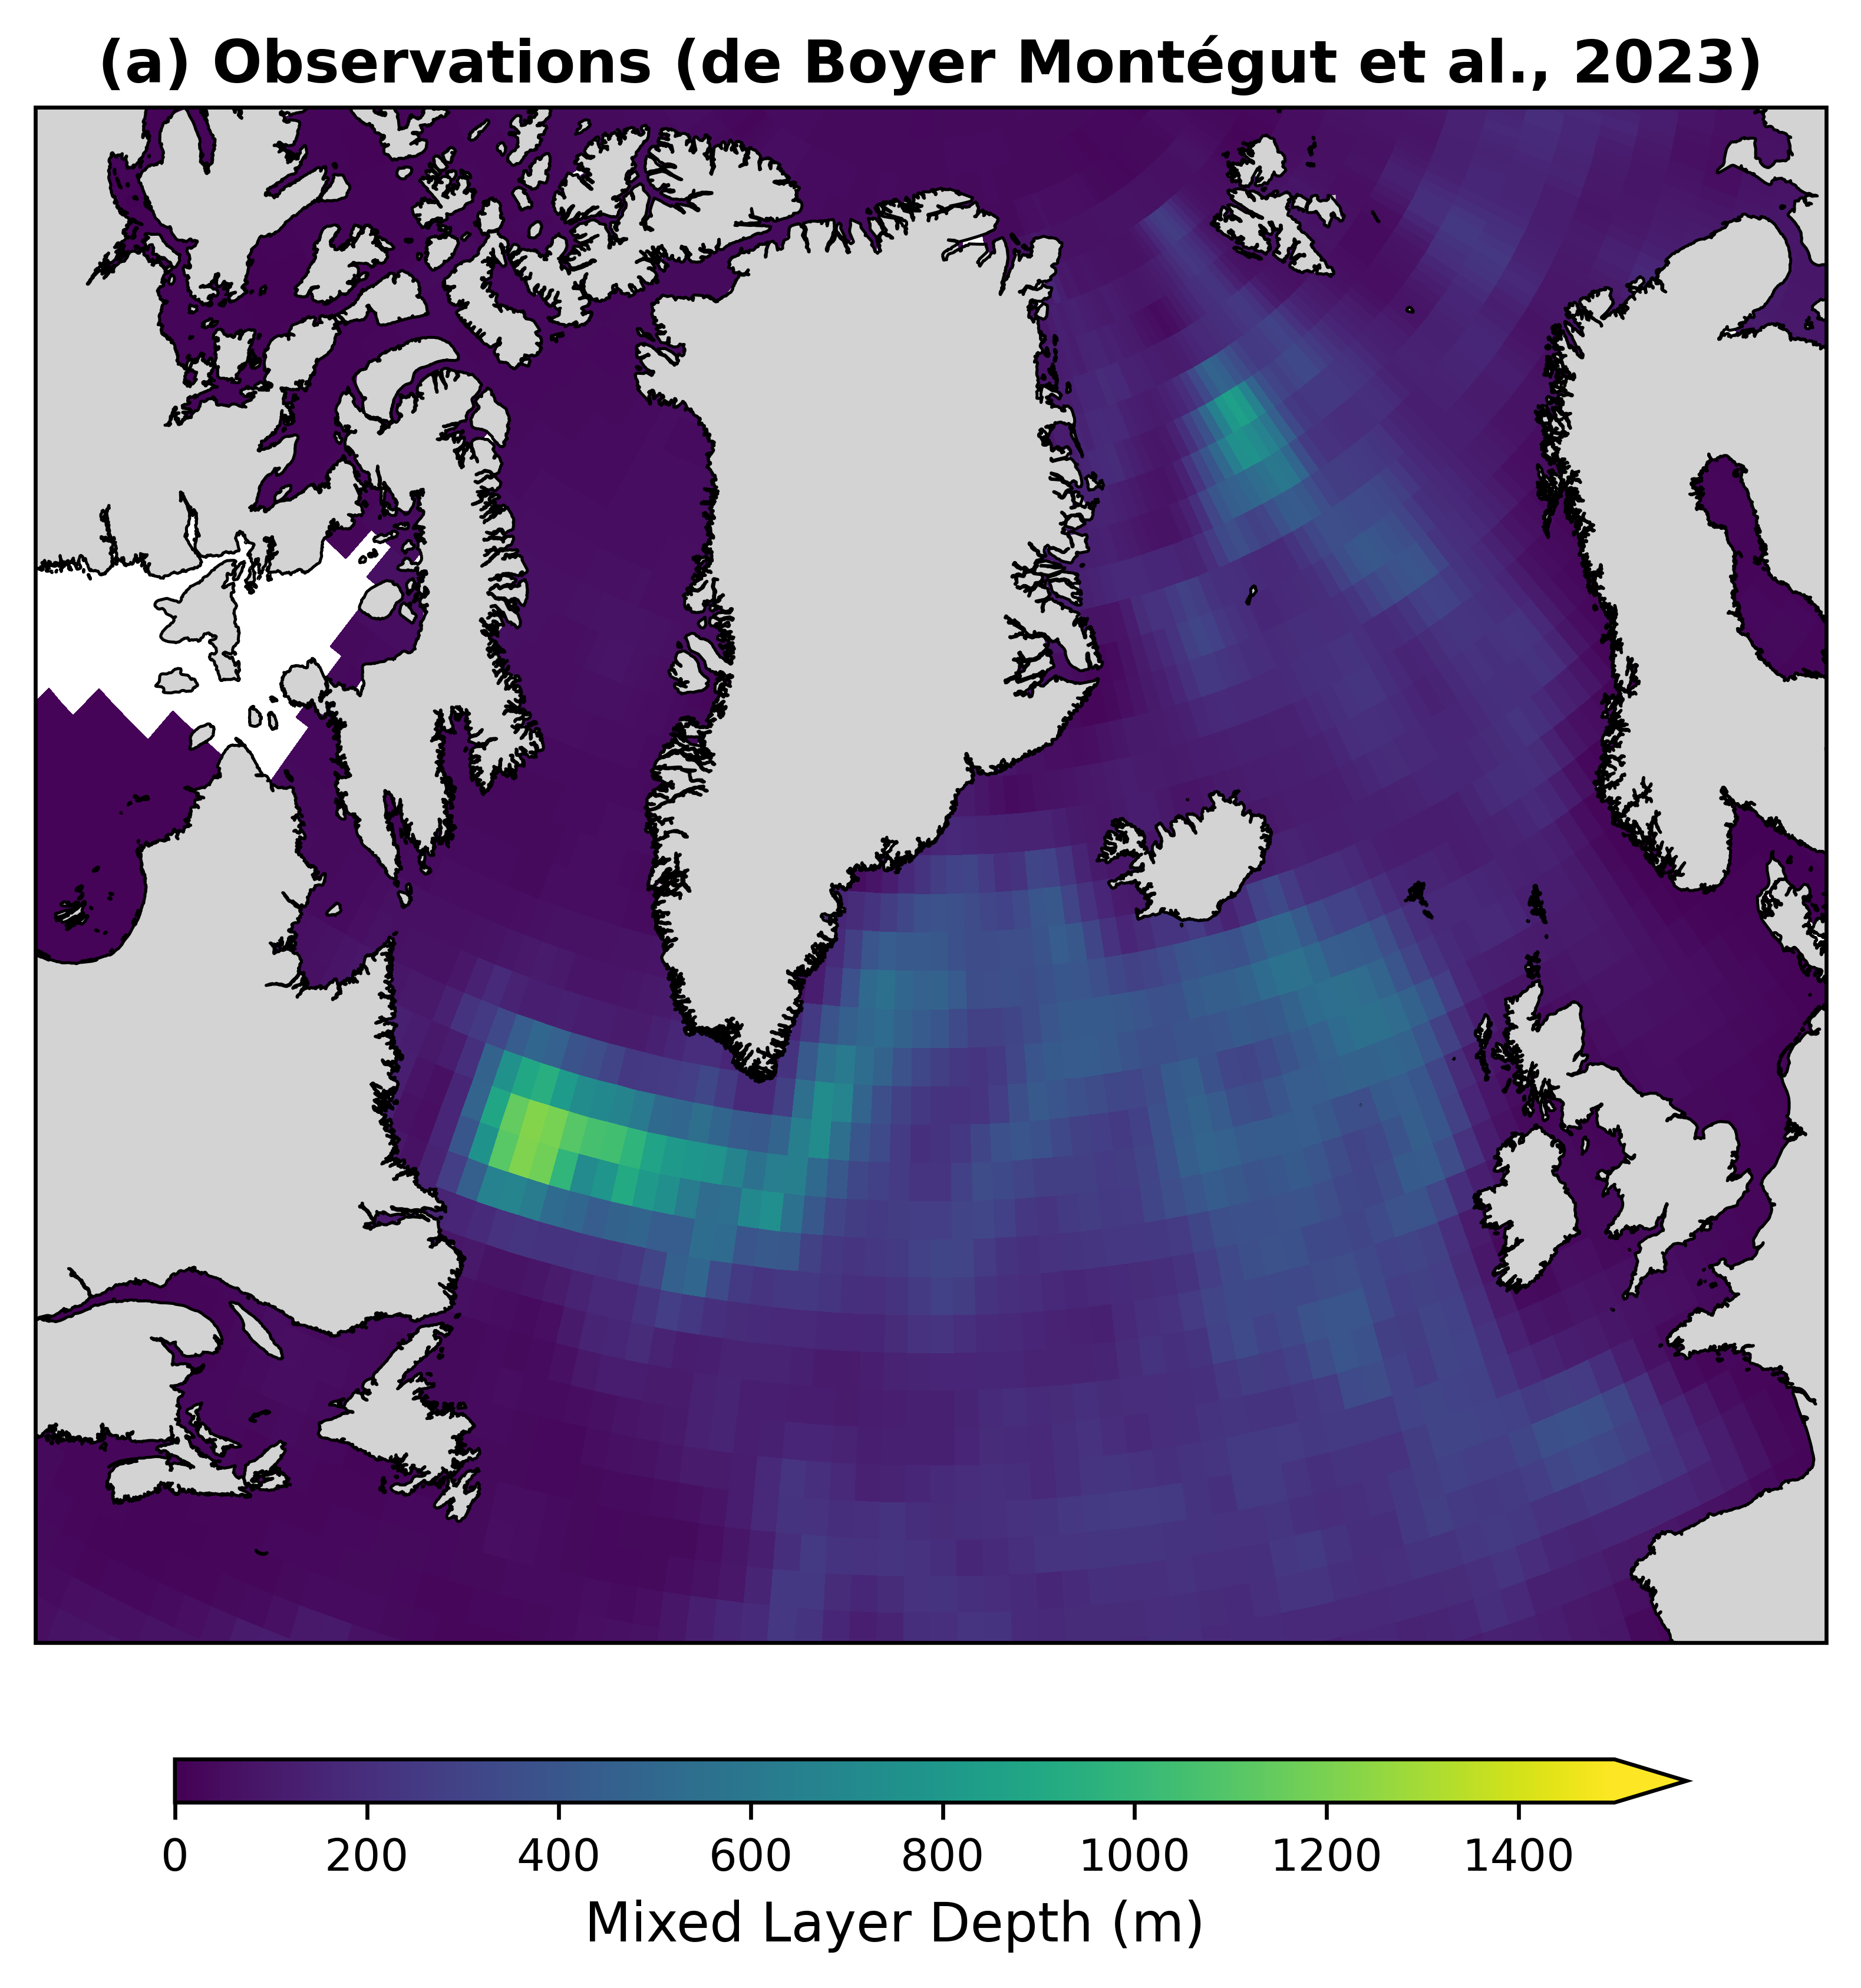

In [ ]:
# Select data
da = (
    ds_obs["mld_dr003"]
    .isel(month=2)
    .sel(latitude=slice(35, None))
)

# Define projections
data_crs = ccrs.PlateCarree()
map_crs = ccrs.Orthographic(
    central_longitude=-35,
    central_latitude=65,
)

# Figure
fig = plt.figure(figsize=(6, 6), dpi=600)
ax = fig.add_subplot(1, 1, 1, projection=map_crs)

# Plot data
im = da.plot(
    ax=ax,
    transform=data_crs,
    x="longitude",
    y="latitude",
    cmap="viridis",
    vmin=0,
    vmax=1500,
    extend="max",
    add_colorbar=False,
    add_labels=False,
    rasterized=True,
)

# Geographic features
ax.add_feature(
    cfeature.LAND,
    facecolor="lightgrey",
    edgecolor="none",
    zorder=2,
)

ax.coastlines(
    resolution="10m",
    linewidth=0.6,
    color="black",
    zorder=3,
)

# Geographic extent
ax.set_extent(
    [-70, 0, 45, 85],
    crs=data_crs,
)

# Colour bar
cbar = fig.colorbar(
    im,
    ax=ax,
    orientation="horizontal",
    extend="max",
    pad=0.06,
    shrink=0.75,
    aspect=35,
)

cbar.set_label("Mixed Layer Depth (m)", fontsize=11)
cbar.ax.tick_params(labelsize=9)

# Title
ax.set_title(
    "(a) Observations (de Boyer Montégut et al., 2023)",
    fontweight='bold',
    fontsize=12,
    pad=5,
)

plt.tight_layout()
# plt.savefig("fig_2a_obs_mld_climatology.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure - eORCA025 SPNA20

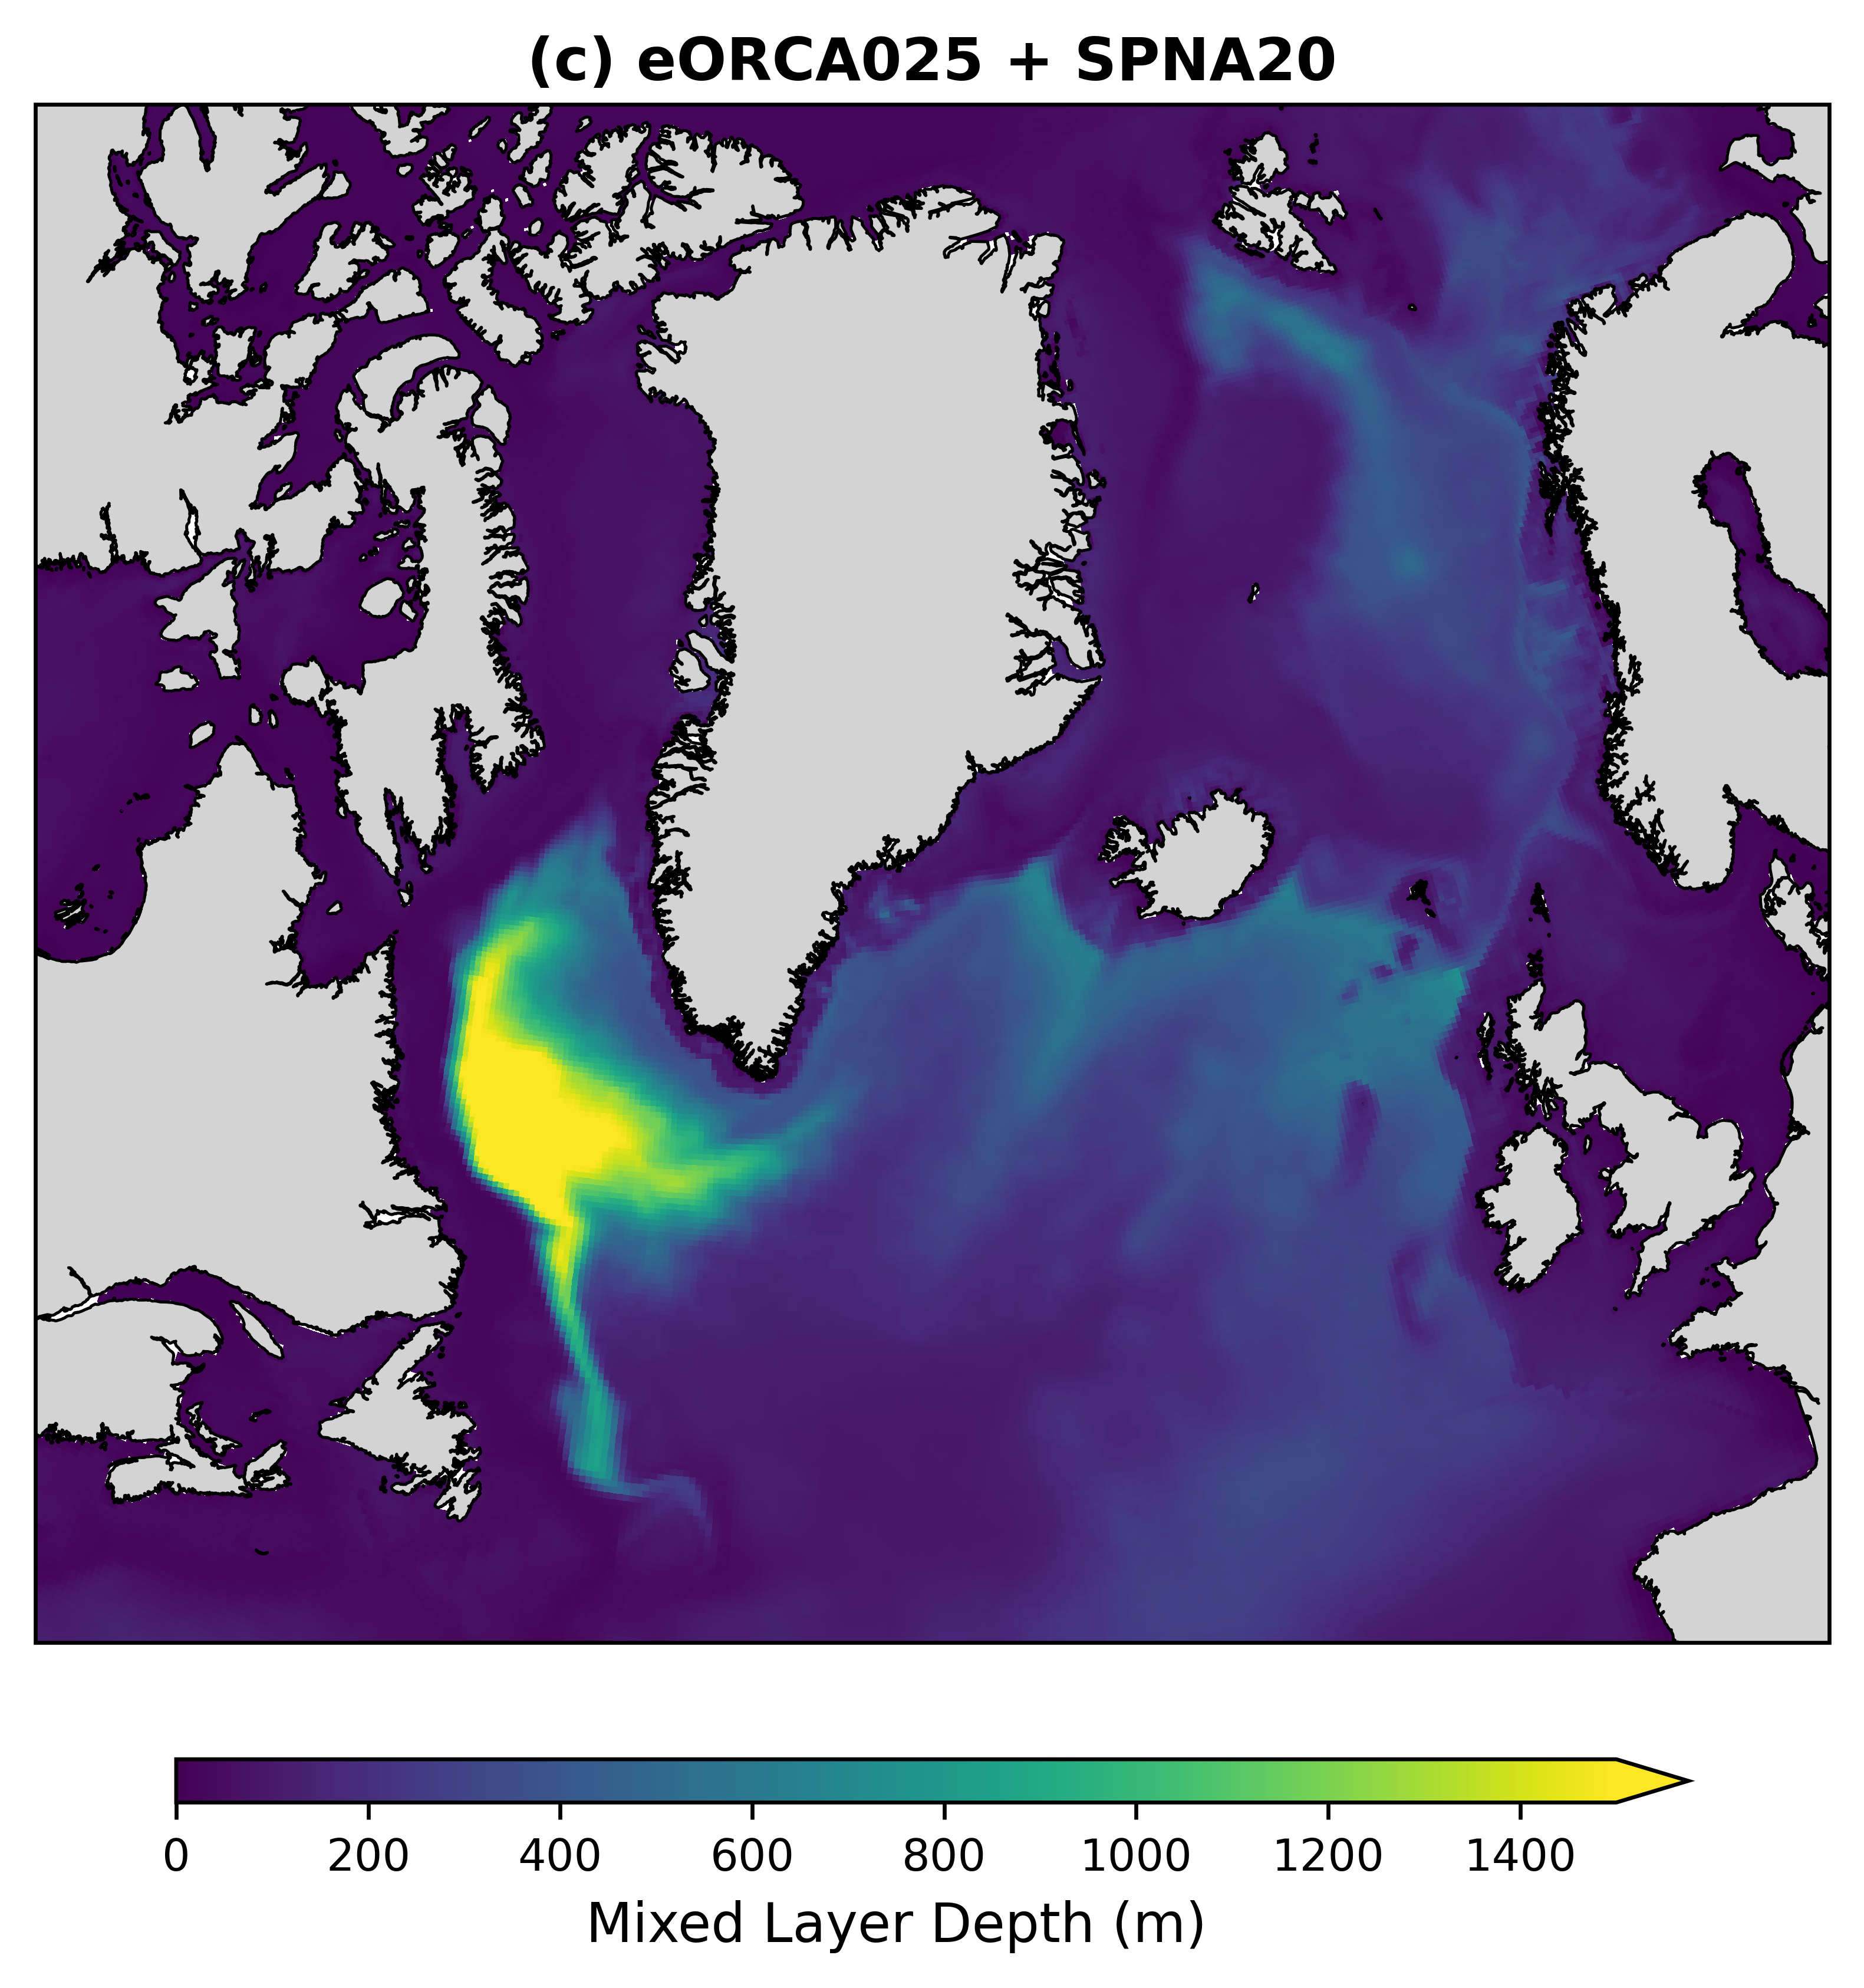

In [ ]:
# Select data
da = (
    nemo["gridT/mlotst"]
    .isel(time_counter=nemo["gridT/time_counter"].dt.month==3)
    .sel(time_counter=slice("1970-01", "2021-12"))
    .mean(dim="time_counter")
)

# Define projections
data_crs = ccrs.PlateCarree()
map_crs = ccrs.Orthographic(
    central_longitude=-35,
    central_latitude=65,
)

# Figure
fig = plt.figure(figsize=(6, 6), dpi=600)
ax = fig.add_subplot(1, 1, 1, projection=map_crs)

# Plot data
im = da.plot(
    ax=ax,
    transform=data_crs,
    x="glamt",
    y="gphit",
    cmap="viridis",
    vmin=0,
    vmax=1500,
    extend="max",
    add_colorbar=False,
    add_labels=False,
    rasterized=True,
)

# Geographic features
ax.add_feature(
    cfeature.LAND,
    facecolor="lightgrey",
    edgecolor="none",
    zorder=2,
)

ax.coastlines(
    resolution="10m",
    linewidth=0.6,
    color="black",
    zorder=3,
)

# Geographic extent
ax.set_extent(
    [-70, 0, 45, 85],
    crs=data_crs,
)

# Colour bar
cbar = fig.colorbar(
    im,
    ax=ax,
    orientation="horizontal",
    extend="max",
    pad=0.06,
    shrink=0.75,
    aspect=35,
)

cbar.set_label("Mixed Layer Depth (m)", fontsize=11)
cbar.ax.tick_params(labelsize=9)

# Title
ax.set_title(
    "(c) eORCA025 + SPNA20",
    fontweight='bold',
    fontsize=12,
    pad=5,
)

plt.tight_layout()
# plt.savefig("fig_2c_eorca025_spna20_mld_climatology.png", dpi=300, bbox_inches="tight")
plt.show()